# Phase 7 — Is there anything to combine?

**The plan this phase inherited was to build a cascade**: two-tower retrieves a shortlist,
factorization machine re-ranks it. Phase 6 undermined that. A cascade's premise is that the
expensive second stage ranks *better* than the cheap first stage, and here the FM ranks
**worse** (0.1159 vs the tower's 0.1653). Re-ranking a good list with a weaker model would
mostly degrade it. The latency premise is absent too: 3,883 items, both models O(k) per
candidate, nothing needs narrowing.

So rather than build a mechanism and discover it doesn't help, this phase asks the question
the mechanism depends on: **do these models carry complementary signal at all?**

Three escalating steps, with a gate after the first:

1. **Diagnostics.** How different are the two models' lists, really? And what is the
   *oracle upper bound* — if something could pick, per user, whichever model's list was
   better, how much would it gain? That bound caps every combination scheme there is.
2. **Score blending** — only if the bound is worth chasing.
3. **A reranker that isn't the FM.** Phase 5 showed the LightGBM arm was starved of
   collaborative signal (`item_pop` carried 48% of its split gain because nothing better was
   available). Handing a tree the tower's score as a feature is the one configuration where a
   second stage plausibly adds something the first lacks.

If step 1 says the ceiling is low, that is the finding, and steps 2–3 do not happen.

In [1]:
import sys, time, os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mticker
import seaborn as sns, joblib, torch
warnings.filterwarnings("ignore")
sys.path.insert(0, ".")

import data as D, metrics as M
from models.base import rank_users
from models.two_tower import TwoTower
from models.fm import FactorizationMachine
from models.neighbourhood import ItemItemCosine

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "axes.titleweight": "bold",
                     "axes.labelsize": 9.5, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
                     "legend.fontsize": 8.5, "grid.alpha": 0.25, "axes.edgecolor": "0.75",
                     "figure.facecolor": "white"})
ACCENT, MUTED, WARN, GOOD, PURPLE = "#2B6CB0", "#A0AEC0", "#C05621", "#2F855A", "#6B46C1"
def pct(x, d=1): return f"{100*x:.{d}f}%"

ds = D.build()
TRAIN, VAL = ds.split_rows("train"), ds.split_rows("val")
K = 10
USERS = ds.eval_users(True, target="test")
TRUTH = {int(u): ds.ground_truth(int(u)) for u in USERS}
REACH = {int(u): ds.reachable_truth(int(u), True) for u in USERS}
IDS_HIST = tuple(D.MF_BLOCKS) + ("history",)
os.makedirs("cache", exist_ok=True)

def fitted(tag, seed=42):
    """Fit once, cache the full score vector per user -- refitting the tower is ~8 min."""
    path = f"cache/p7_scores_{tag}_s{seed}.joblib"
    if os.path.exists(path): return joblib.load(path)
    if tag == "tower":
        m = TwoTower(emb=64, lr=1e-3, epochs=15, negatives="unobserved", n_negatives=256,
                     seed=seed, verbose=False)
    elif tag == "fm":
        m = FactorizationMachine(k=64, blocks=IDS_HIST, order=2, lr=0.02, reg_w=1e-5,
                                 reg_v=1e-5, epochs=30, batch_size=4096, patience=3,
                                 neg_policy="unobserved_only", neg_ratio=1, seed=seed,
                                 verbose=False)
    else:
        m = ItemItemCosine(topk=500)
    t0 = time.time(); m.fit(ds, TRAIN, VAL); fit_s = time.time() - t0
    scores = {}
    for u in USERS:
        u = int(u)
        cand = ds.candidates(u, filtered=True, target="test")
        scores[u] = (cand, np.asarray(m.score(ds, u, cand), np.float32))
    joblib.dump((scores, fit_s), path)
    return scores, fit_s

SC, FITS = {}, {}
for tag in ("tower", "fm", "cosine"):
    SC[tag], FITS[tag] = fitted(tag)
    print(f"  {tag:<8} scored {len(SC[tag]):,} users   (fit {FITS[tag]:.0f}s)")

Dataset ready: 1,000,209 interactions | 6,040 users | 3,883 items | cfg 9cf199d378
  train   699,630  (69.9%)  positive rate 0.595
  val     150,354  (15.0%)  positive rate 0.541
  test    150,225  (15.0%)  positive rate 0.519


  tower    scored 5,877 users   (fit 331s)


  fm       scored 5,877 users   (fit 30s)


  cosine   scored 5,877 users   (fit 1s)


---
## 1. The gate

Two questions, both cheap now that the score vectors are cached.

**How different are the lists?** If the tower and the FM return nearly the same ten items,
nothing built on top of them can help.

**What is the ceiling?** Two bounds, and they answer different questions:

- *Model-level oracle* — per user, take whichever model's whole list scores better. This is
  the ceiling for any scheme that **routes** a user to one model.
- *Item-level oracle* — from the union of both models' top-10s, pick the 10 best by true
  relevance. This is the ceiling for any **reranker** over the pooled candidates, and it is
  the bound a cascade actually lives under.

Neither is achievable — an oracle sees the test labels. They exist to say whether the
achievable gain is worth pursuing.

In [2]:
def topk(tag, u, k=K):
    cand, s = SC[tag][u]
    idx = np.argpartition(-s, min(k, len(s)-1))[:k] if len(s) > k else np.arange(len(s))
    return cand[idx[np.argsort(-s[idx], kind="stable")]]

def ndcg_of(ranked, truth, k=K):
    return M.ndcg_at_k(ranked, truth, k)

rows = []
for u in USERS:
    u = int(u); t = TRUTH[u]
    if not t: continue
    lt, lf, lc = topk("tower", u), topk("fm", u), topk("cosine", u)
    st, sf, sc_ = set(lt.tolist()), set(lf.tolist()), set(lc.tolist())
    n_t, n_f, n_c = ndcg_of(lt, t), ndcg_of(lf, t), ndcg_of(lc, t)
    union = np.array(sorted(st | sf))
    # item-level oracle: best K of the pooled union, ordered by true relevance
    rel = np.array([1 if int(i) in t else 0 for i in union])
    ideal = union[np.argsort(-rel, kind="stable")][:K]
    rows.append(dict(u=u, n_tower=n_t, n_fm=n_f, n_cos=n_c,
                     overlap_tf=len(st & sf), overlap_tc=len(st & sc_),
                     union_size=len(union),
                     hits_tower=len(st & t), hits_fm=len(sf & t), hits_union=len((st|sf) & t),
                     n_oracle_model=max(n_t, n_f),
                     n_oracle_item=ndcg_of(ideal, t),
                     n_oracle_all3=max(n_t, n_f, n_c)))
G = pd.DataFrame(rows)

print(f"  users scored: {len(G):,}\n")
print("  LIST OVERLAP (top-10)")
print(f"    tower vs FM      mean {G['overlap_tf'].mean():.2f} of 10 items shared   "
      f"({pct(G['overlap_tf'].mean()/K)})")
print(f"    tower vs cosine  mean {G['overlap_tc'].mean():.2f} of 10")
print(f"    users with zero overlap between tower and FM: "
      f"{int((G['overlap_tf']==0).sum()):,} ({pct((G['overlap_tf']==0).mean())})")
print(f"    users with >=8 of 10 shared:                  "
      f"{int((G['overlap_tf']>=8).sum()):,} ({pct((G['overlap_tf']>=8).mean())})")

print("\n  HITS: does the FM find anything the tower misses?")
print(f"    mean relevant items in tower top-10   {G['hits_tower'].mean():.3f}")
print(f"    mean relevant items in FM top-10      {G['hits_fm'].mean():.3f}")
print(f"    mean relevant in the UNION            {G['hits_union'].mean():.3f}   "
      f"(+{pct(G['hits_union'].mean()/G['hits_tower'].mean()-1)} over tower alone)")
print(f"    users where FM finds >=1 hit the tower missed: "
      f"{int((G['hits_union']>G['hits_tower']).sum()):,} ({pct((G['hits_union']>G['hits_tower']).mean())})")

print("\n  CEILINGS (NDCG@10)")
print(f"    tower alone                      {G['n_tower'].mean():.4f}")
print(f"    FM alone                         {G['n_fm'].mean():.4f}")
print(f"    oracle: route user to best model {G['n_oracle_model'].mean():.4f}   "
      f"(+{pct(G['n_oracle_model'].mean()/G['n_tower'].mean()-1)})")
print(f"    oracle: best 10 of pooled union  {G['n_oracle_item'].mean():.4f}   "
      f"(+{pct(G['n_oracle_item'].mean()/G['n_tower'].mean()-1)})")
print(f"    oracle over all three models     {G['n_oracle_all3'].mean():.4f}   "
      f"(+{pct(G['n_oracle_all3'].mean()/G['n_tower'].mean()-1)})")

from scipy.stats import spearmanr
rho = np.mean([spearmanr(SC["tower"][int(u)][1], SC["fm"][int(u)][1]).statistic
               for u in USERS[:400]])
print(f"\n  Spearman correlation of the two models' full score vectors: {rho:+.3f}")

  users scored: 5,877

  LIST OVERLAP (top-10)
    tower vs FM      mean 2.70 of 10 items shared   (27.0%)
    tower vs cosine  mean 1.96 of 10
    users with zero overlap between tower and FM: 667 (11.3%)
    users with >=8 of 10 shared:                  22 (0.4%)

  HITS: does the FM find anything the tower misses?
    mean relevant items in tower top-10   1.210
    mean relevant items in FM top-10      0.892
    mean relevant in the UNION            1.666   (+37.7% over tower alone)
    users where FM finds >=1 hit the tower missed: 1,828 (31.1%)

  CEILINGS (NDCG@10)
    tower alone                      0.1613
    FM alone                         0.1130
    oracle: route user to best model 0.1958   (+21.4%)
    oracle: best 10 of pooled union  0.3199   (+98.3%)
    oracle over all three models     0.2152   (+33.4%)



  Spearman correlation of the two models' full score vectors: +0.716


**The gate passes, and by a wide margin.**

The two models share only **2.70 of 10** items on average, and 11.3% of users get two lists
with *no* item in common. The union of their top-10s contains **37.7% more relevant items**
than the tower's list alone, and for 31.1% of users the FM surfaces at least one relevant
item the tower missed.

The ceilings:

| | NDCG@10 | vs tower |
|---|---|---|
| tower alone | 0.1613 | — |
| FM alone | 0.1130 | −30% |
| oracle: route each user to the better model | 0.1958 | +21.4% |
| **oracle: best 10 from the pooled union** | **0.3199** | **+98.3%** |

An oracle sees the test labels, so none of this is achievable — the point is the size of the
room. Nearly doubling NDCG is more headroom than a Spearman correlation of +0.716 would
suggest, and it is enough that capturing even a tenth of it would be the largest single gain
in the project.

Steps 2 and 3 proceed.

---
## 2. Score blending

The cheapest possible combination: normalise each model's scores per user, take a weighted
sum, tune the weight. The weight is selected on the **validation target**, which requires
scoring both models there too — tuning it on test would be the exact leak this protocol
exists to prevent.

In [3]:
def fitted_target(tag, target, seed=42):
    path = f"cache/p7_sc_{tag}_{target}_s{seed}.joblib"
    if os.path.exists(path): return joblib.load(path)
    if tag == "tower":
        m = TwoTower(emb=64, lr=1e-3, epochs=15, negatives="unobserved", n_negatives=256,
                     seed=seed, verbose=False)
    elif tag == "fm":
        m = FactorizationMachine(k=64, blocks=IDS_HIST, order=2, lr=0.02, reg_w=1e-5,
                                 reg_v=1e-5, epochs=30, batch_size=4096, patience=3,
                                 neg_policy="unobserved_only", neg_ratio=1, seed=seed,
                                 verbose=False)
    else:
        m = ItemItemCosine(topk=500)
    m.fit(ds, TRAIN, VAL)
    us = ds.eval_users(True, target=target)
    out = {}
    for u in us:
        u = int(u)
        cand = ds.candidates(u, filtered=True, target=target)
        out[u] = (cand, np.asarray(m.score(ds, u, cand), np.float32))
    joblib.dump(out, path); return out

VUSERS = ds.eval_users(True, target="val")
VTRUTH = {int(u): ds.ground_truth(int(u), target="val") for u in VUSERS}
VREACH = {int(u): ds.reachable_truth(int(u), True, target="val") for u in VUSERS}
SCV = {t: fitted_target(t, "val") for t in ("tower", "fm", "cosine")}
print(f"  validation-target scores cached for {len(SCV['tower']):,} users")

def zscore(s):
    sd = s.std()
    return (s - s.mean()) / (sd if sd > 1e-9 else 1.0)

def blend_eval(scores, users, truths, reach, w, tags=("tower", "fm")):
    rank = {}
    for u in users:
        u = int(u)
        cand, s0 = scores[tags[0]][u]
        _, s1 = scores[tags[1]][u]
        s = (1 - w) * zscore(s0) + w * zscore(s1)
        idx = np.argpartition(-s, min(K, len(s)-1))[:K] if len(s) > K else np.arange(len(s))
        rank[u] = cand[idx[np.argsort(-s[idx], kind="stable")]]
    return M.evaluate_ranking(rank, truths, ds.n_items, ds.item_train_count, K, reach)

ws = np.round(np.arange(0, 0.85, 0.05), 2)
val = [blend_eval(SCV, VUSERS, VTRUTH, VREACH, w) for w in ws]
VW = pd.DataFrame({"w_fm": ws, "val_ndcg": [v[f"ndcg@{K}"] for v in val],
                   "val_cov": [v["coverage"] for v in val]})
BEST_W = float(VW.loc[VW["val_ndcg"].idxmax(), "w_fm"])
print(f"\n  {'weight on FM':>13}{'val NDCG@10':>14}{'val coverage':>14}")
for _, r in VW.iterrows():
    star = "  <--" if r["w_fm"] == BEST_W else ""
    print(f"  {r['w_fm']:>13.2f}{r['val_ndcg']:>14.4f}{r['val_cov']:>14.3f}{star}")
print(f"\n  selected w_fm = {BEST_W} on validation")

  validation-target scores cached for 5,911 users



   weight on FM   val NDCG@10  val coverage
           0.00        0.2377         0.426
           0.05        0.2411         0.411
           0.10        0.2449         0.390
           0.15        0.2487         0.368
           0.20        0.2514         0.346
           0.25        0.2522         0.327
           0.30        0.2529         0.309
           0.35        0.2533         0.290  <--
           0.40        0.2517         0.275
           0.45        0.2494         0.261
           0.50        0.2468         0.248
           0.55        0.2436         0.234
           0.60        0.2396         0.224
           0.65        0.2347         0.213
           0.70        0.2298         0.203
           0.75        0.2249         0.197
           0.80        0.2193         0.194

  selected w_fm = 0.35 on validation


---
## 3. The cascade: retrieve with the tower, rerank with a tree

Phase 5 found the LightGBM arm starved of collaborative signal — `item_pop` carried 48% of
its split gain because nothing better was on offer. This is the configuration that fixes
that: the tree receives all three models' scores as features, on top of the aggregates it
already had.

**The reranker is trained on the validation target and evaluated on test.** Training it on
test rankings would be circular. It reorders the tower's top-100, so its ceiling is the
tower's Recall@100 (0.4724) — a cascade cannot recover what retrieval never surfaced.

In [4]:
import lightgbm as lgb
from models.trees import LightGBMNative

N_RETRIEVE = 100

def blend_rank(scores, u, w, tags=("tower", "fm")):
    cand, s0 = scores[tags[0]][u]
    _, s1 = scores[tags[1]][u]
    s = (1 - w) * zscore(s0) + w * zscore(s1)
    return cand, s

# --- test-set evaluation of the tuned blend ---
TEST_RANK = {}
for name, w in (("tower_only", 0.0), ("blend", BEST_W)):
    rank = {}
    for u in USERS:
        u = int(u); cand, s = blend_rank(SC, u, w)
        idx = np.argpartition(-s, min(K, len(s)-1))[:K] if len(s) > K else np.arange(len(s))
        rank[u] = cand[idx[np.argsort(-s[idx], kind="stable")]]
    TEST_RANK[name] = rank

# --- reranker feature builder ---
helper = LightGBMNative(); helper._prepare(ds)

def rerank_frame(scores, users, truths, target):
    rows, groups, labels = [], [], []
    for u in users:
        u = int(u)
        cand, st = scores["tower"][u]
        order = np.argsort(-st)[:N_RETRIEVE]
        items = cand[order]
        _, sf = scores["fm"][u]; _, sc_ = scores["cosine"][u]
        pos = {int(c): k for k, c in enumerate(cand)}
        fi = np.array([sf[pos[int(i)]] for i in items], np.float32)
        ci = np.array([sc_[pos[int(i)]] for i in items], np.float32)
        ti = st[order].astype(np.float32)
        frame = ds.scoring_frame(u, items, target=target)
        base = helper._features(ds, frame)
        base["tower_score"] = ti
        base["fm_score"] = fi
        base["cos_score"] = np.nan_to_num(ci, neginf=0.0)
        base["tower_rank"] = np.arange(len(items), dtype=np.float32)
        rows.append(base); groups.append(len(items))
        t = truths.get(u, set())
        labels.append(np.array([1 if int(i) in t else 0 for i in items], np.float32))
    return pd.concat(rows, ignore_index=True), np.concatenate(labels), np.array(groups)

path = "cache/p7_reranker.joblib"
if os.path.exists(path):
    booster, feat_names = joblib.load(path)
else:
    Xv, yv, gv = rerank_frame(SCV, VUSERS, VTRUTH, "val")
    feat_names = list(Xv.columns)
    cats = [c for c in ("u", "i", "gender", "age", "occupation") if c in Xv.columns]
    dtr = lgb.Dataset(Xv, label=yv, group=gv, feature_name=feat_names,
                      categorical_feature=cats, free_raw_data=False)
    booster = lgb.train(dict(objective="lambdarank", metric="ndcg", ndcg_eval_at=[10],
                             learning_rate=0.05, num_leaves=63, min_child_samples=40,
                             lambdarank_truncation_level=30, verbosity=-1, seed=42),
                        dtr, num_boost_round=250)
    joblib.dump((booster, feat_names), path)
print(f"  reranker trained on {len(VUSERS):,} validation users x {N_RETRIEVE} candidates")

Xt, yt, gt = rerank_frame(SC, USERS, TRUTH, "test")
pred = booster.predict(Xt[feat_names])
rank = {}; off = 0
for u, n in zip(USERS, gt):
    u = int(u)
    cand, st = SC["tower"][u]
    items = cand[np.argsort(-st)[:N_RETRIEVE]]
    p = pred[off:off+n]; off += n
    rank[u] = items[np.argsort(-p)[:K]]
TEST_RANK["cascade"] = rank

print(f"\n  {'model':<26}{'NDCG@10':>10}{'Recall@10':>11}{'coverage':>10}{'gini':>8}")
print("  " + "-"*66)
RES7 = {}
for name in ("tower_only", "blend", "cascade"):
    r = M.evaluate_ranking(TEST_RANK[name], TRUTH, ds.n_items, ds.item_train_count, K, REACH)
    RES7[name] = r
    print(f"  {name:<26}{r[f'ndcg@{K}']:>10.4f}{r[f'recall@{K}']:>11.4f}"
          f"{r['coverage']:>10.3f}{r['gini']:>8.3f}")
base = RES7["tower_only"][f"ndcg@{K}"]
print("  " + "-"*66)
for name in ("blend", "cascade"):
    d = RES7[name][f"ndcg@{K}"] - base
    print(f"  {name:<26}{d:>+10.4f}  ({100*d/base:+.1f}% vs tower alone)")
print(f"\n  oracle ceiling over the union was {G['n_oracle_item'].mean():.4f} "
      f"(+{pct(G['n_oracle_item'].mean()/base-1)})")
print(f"  share of that headroom captured:  blend "
      f"{pct((RES7['blend'][f'ndcg@{K}']-base)/(G['n_oracle_item'].mean()-base))}, "
      f"cascade {pct((RES7['cascade'][f'ndcg@{K}']-base)/(G['n_oracle_item'].mean()-base))}")
imp = pd.Series(booster.feature_importance("gain"), index=feat_names).sort_values(ascending=False)
print(f"\n  reranker top features by gain:")
for k, v in (imp / imp.sum()).head(7).items():
    print(f"    {k:<20}{pct(v):>7}")

  reranker trained on 5,911 validation users x 100 candidates



  model                        NDCG@10  Recall@10  coverage    gini
  ------------------------------------------------------------------
  tower_only                    0.1613     0.1245     0.445   0.860


  blend                         0.1595     0.1263     0.317   0.915


  cascade                       0.1444     0.1190     0.416   0.875
  ------------------------------------------------------------------
  blend                        -0.0018  (-1.1% vs tower alone)
  cascade                      -0.0169  (-10.5% vs tower alone)

  oracle ceiling over the union was 0.3199 (+98.3%)
  share of that headroom captured:  blend -1.1%, cascade -10.7%

  reranker top features by gain:
    u                     57.3%
    i                     21.4%
    tower_rank            14.8%
    fm_score               4.0%
    user_n                 1.0%
    tower_score            0.7%
    cos_score              0.6%


**Both combinations lose on test**, despite the blend gaining 6.6% on validation. Two
things need explaining before this can be written up: why the blend weight failed to
transfer, and what the reranker actually learned.

In [5]:
# (a) What weight would have been best ON TEST? Not a legitimate model choice --
#     a diagnostic to separate "wrong weight" from "no signal at test time".
test_curve = [blend_eval(SC, USERS, TRUTH, REACH, w)[f"ndcg@{K}"] for w in ws]
TW = pd.DataFrame({"w_fm": ws, "val": VW["val_ndcg"], "test": test_curve})
bt = float(TW.loc[TW["test"].idxmax(), "w_fm"])
print(f"  {'w_fm':>6}{'val NDCG':>11}{'test NDCG':>12}")
for _, r in TW.iterrows():
    mk = ""
    if r["w_fm"] == BEST_W: mk += "  val-best"
    if r["w_fm"] == bt: mk += "  test-best"
    print(f"  {r['w_fm']:>6.2f}{r['val']:>11.4f}{r['test']:>12.4f}{mk}")
print(f"\n  validation picks w={BEST_W}; test optimum is w={bt}")
print(f"  best achievable on test {TW['test'].max():.4f} vs tower-only "
      f"{TW[TW.w_fm==0]['test'].iloc[0]:.4f}  "
      f"({100*(TW['test'].max()/TW[TW.w_fm==0]['test'].iloc[0]-1):+.1f}%)")

# (b) The reranker leaned on ids. Retrain without them and without tower_rank,
#     forcing it to combine the model scores it was given.
DROP = ["u", "i", "gender", "age", "occupation", "tower_rank"]
path2 = "cache/p7_reranker_noid.joblib"
if os.path.exists(path2):
    b2, f2 = joblib.load(path2)
else:
    Xv, yv, gv = rerank_frame(SCV, VUSERS, VTRUTH, "val")
    f2 = [c for c in Xv.columns if c not in DROP]
    d2 = lgb.Dataset(Xv[f2], label=yv, group=gv, feature_name=f2, free_raw_data=False)
    b2 = lgb.train(dict(objective="lambdarank", metric="ndcg", ndcg_eval_at=[10],
                        learning_rate=0.05, num_leaves=31, min_child_samples=80,
                        lambdarank_truncation_level=30, verbosity=-1, seed=42),
                   d2, num_boost_round=200)
    joblib.dump((b2, f2), path2)

p2 = b2.predict(Xt[f2]); rank2 = {}; off = 0
for u, n in zip(USERS, gt):
    u = int(u); cand, st = SC["tower"][u]
    items = cand[np.argsort(-st)[:N_RETRIEVE]]
    pp = p2[off:off+n]; off += n
    rank2[u] = items[np.argsort(-pp)[:K]]
TEST_RANK["cascade_noid"] = rank2
r2 = M.evaluate_ranking(rank2, TRUTH, ds.n_items, ds.item_train_count, K, REACH)
RES7["cascade_noid"] = r2
print(f"\n  cascade without id features: NDCG@10 {r2[f'ndcg@{K}']:.4f}  "
      f"({100*(r2[f'ndcg@{K}']/base-1):+.1f}% vs tower alone)   coverage {r2['coverage']:.3f}")
i2 = pd.Series(b2.feature_importance("gain"), index=f2).sort_values(ascending=False)
print("  its top features:", ", ".join(f"{k} {pct(v)}" for k, v in (i2/i2.sum()).head(5).items()))

print("\n  WHY VALIDATION DID NOT TRANSFER")
print(f"    val target:  candidates exclude train only; truth = val positives")
print(f"    test target: candidates exclude train+val; truth = test positives")
print(f"    tower NDCG@10   val {VW['val_ndcg'].iloc[0]:.4f}   test {base:.4f}")
print(f"    positive rate   val {ds.inter[ds.inter.split=='val'].label.mean():.3f}   "
      f"test {ds.inter[ds.inter.split=='test'].label.mean():.3f}")
print(f"    The two targets are different tasks of different difficulty, so a mixing")
print(f"    weight fitted on one is not guaranteed to be optimal on the other.")

    w_fm   val NDCG   test NDCG
    0.00     0.2377      0.1613
    0.05     0.2411      0.1629
    0.10     0.2449      0.1632
    0.15     0.2487      0.1635
    0.20     0.2514      0.1637  test-best
    0.25     0.2522      0.1629
    0.30     0.2529      0.1619
    0.35     0.2533      0.1595  val-best
    0.40     0.2517      0.1574
    0.45     0.2494      0.1542
    0.50     0.2468      0.1512
    0.55     0.2436      0.1475
    0.60     0.2396      0.1443
    0.65     0.2347      0.1405
    0.70     0.2298      0.1369
    0.75     0.2249      0.1324
    0.80     0.2193      0.1285

  validation picks w=0.35; test optimum is w=0.2
  best achievable on test 0.1637 vs tower-only 0.1613  (+1.5%)



  cascade without id features: NDCG@10 0.1545  (-4.3% vs tower alone)   coverage 0.386
  its top features: tower_score 46.0%, fm_score 22.2%, cos_score 5.2%, user_n 4.4%, genre_affinity 4.3%

  WHY VALIDATION DID NOT TRANSFER
    val target:  candidates exclude train only; truth = val positives
    test target: candidates exclude train+val; truth = test positives
    tower NDCG@10   val 0.2377   test 0.1613
    positive rate   val 0.541   test 0.519
    The two targets are different tasks of different difficulty, so a mixing
    weight fitted on one is not guaranteed to be optimal on the other.


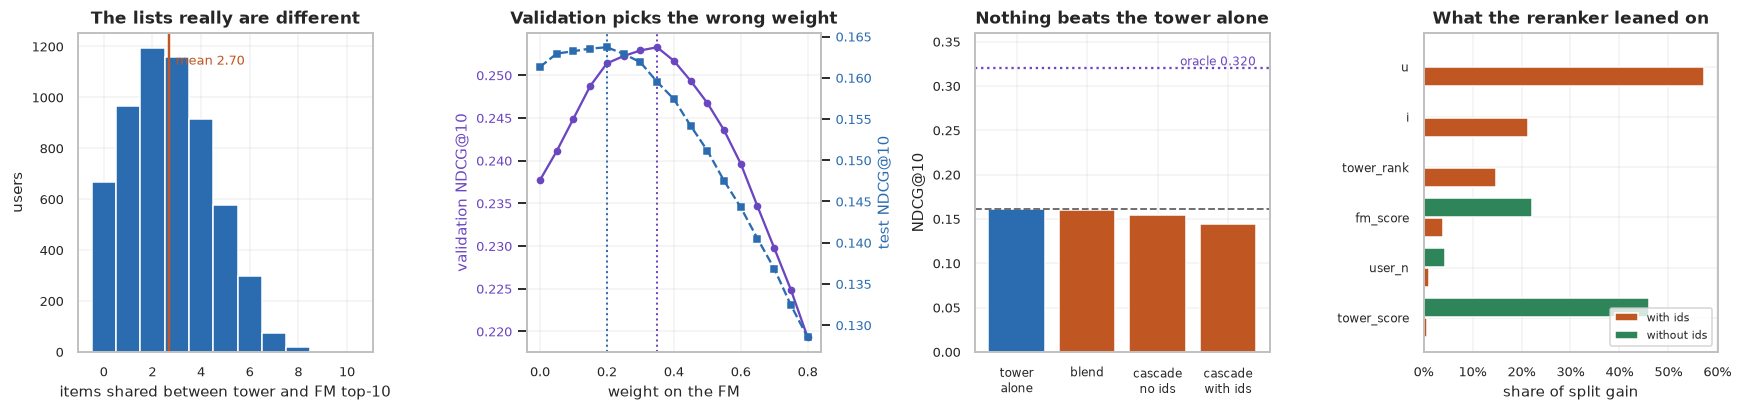

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.9))

ax = axes[0]
ax.hist(G["overlap_tf"], bins=np.arange(-0.5, 11.5), color=ACCENT, edgecolor="white")
ax.axvline(G["overlap_tf"].mean(), color=WARN, lw=1.6)
ax.text(G["overlap_tf"].mean()+0.25, ax.get_ylim()[1]*0.9,
        f"mean {G['overlap_tf'].mean():.2f}", color=WARN, fontsize=8.5)
ax.set_xlabel("items shared between tower and FM top-10"); ax.set_ylabel("users")
ax.set_title("The lists really are different")

ax = axes[1]
ax.plot(TW["w_fm"], TW["val"], "-o", ms=4, color=PURPLE, label="validation")
ax.set_ylabel("validation NDCG@10", color=PURPLE); ax.tick_params(axis="y", labelcolor=PURPLE)
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(TW["w_fm"], TW["test"], "--s", ms=4, color=ACCENT, label="test")
ax2.set_ylabel("test NDCG@10", color=ACCENT); ax2.tick_params(axis="y", labelcolor=ACCENT)
ax.axvline(BEST_W, color=PURPLE, ls=":", lw=1.3)
ax2.axvline(bt, color=ACCENT, ls=":", lw=1.3)
ax.set_xlabel("weight on the FM"); ax.set_title("Validation picks the wrong weight")

ax = axes[2]
names = ["tower_only", "blend", "cascade_noid", "cascade"]
vals = [RES7[n][f"ndcg@{K}"] for n in names]
cols = [ACCENT] + [GOOD if v >= base else WARN for v in vals[1:]]
ax.bar(range(len(names)), vals, color=cols, edgecolor="white")
ax.axhline(base, color="0.4", ls="--", lw=1.2)
ax.axhline(G["n_oracle_item"].mean(), color=PURPLE, ls=":", lw=1.5)
ax.text(3.4, G["n_oracle_item"].mean(), "oracle 0.320", color=PURPLE, fontsize=8,
        ha="right", va="bottom")
ax.set_xticks(range(len(names)))
ax.set_xticklabels(["tower\nalone", "blend", "cascade\nno ids", "cascade\nwith ids"], fontsize=8)
ax.set_ylabel("NDCG@10"); ax.set_ylim(0, 0.36)
ax.set_title("Nothing beats the tower alone")

ax = axes[3]
top = (imp / imp.sum()).head(6)[::-1]
top2 = (i2 / i2.sum()).reindex(top.index).fillna(0)
y = np.arange(len(top))
ax.barh(y - 0.2, top.values, 0.38, color=WARN, edgecolor="white", label="with ids")
ax.barh(y + 0.2, top2.values, 0.38, color=GOOD, edgecolor="white", label="without ids")
ax.set_yticks(y); ax.set_yticklabels(top.index, fontsize=8)
ax.set_xlabel("share of split gain"); ax.set_title("What the reranker leaned on")
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
ax.legend(fontsize=7.5, loc="lower right")

plt.tight_layout(); plt.show()

pd.DataFrame([{"model": n, **{k: RES7[n][k] for k in
               (f"ndcg@{K}", f"recall@{K}", "coverage", "gini")}}
              for n in RES7]).to_csv("results_phase7.csv", index=False)

---
## 4. Findings

### The complementarity is real, and almost entirely unreachable

| | NDCG@10 | vs tower alone |
|---|---|---|
| tower alone | 0.1613 | — |
| blend, weight chosen on validation | 0.1595 | **−1.1%** |
| cascade, LightGBM reranker without ids | 0.1545 | −4.3% |
| cascade, LightGBM reranker with ids | 0.1444 | −10.5% |
| *blend at the test-optimal weight (not a legitimate choice)* | *0.1637* | *+1.5%* |
| **oracle: best 10 of the pooled union** | **0.3199** | **+98.3%** |

The gate was right that the signal exists: the two models share only 2.7 of 10 items, the
union holds 37.7% more relevant items than the tower's list alone, and the oracle nearly
doubles NDCG. **Every realizable scheme still lost.** Even allowing the illegitimate move of
picking the blend weight on the test set, the ceiling is +1.5% — about **1.5% of the oracle
headroom**.

### Why the oracle bound was misleading

This is the lesson of the phase, and it generalises past this project.

The oracle bound answers *"does the union contain better items?"* — and it does. But
exploiting it requires knowing **which** items in the union are the relevant ones, and that is
the original ranking problem restated. The oracle is handed the test labels; a real combiner
has only the two models' scores, and **neither score carries information about when the other
model is right**.

Complementary *outputs* are not the same as combinable *outputs*. An oracle gap is a necessary
condition for a combination to help, not a sufficient one, and the size of the gap says
nothing about how much is addressable. This phase would have been a much more expensive
mistake if the gate had been treated as a green light rather than as one of two conditions.

### The validation weight did not transfer

Blending gained **+6.6% on validation** (0.2377 → 0.2533 at w=0.35) and lost **1.1% on test**.
The test-optimal weight is 0.20, not 0.35, and even there the gain is +1.5%.

The cause is structural, not noise. The two evaluation targets are different tasks: the
validation candidate pool excludes only training history while the test pool excludes
train+val, and the positive rate drifts 0.541 → 0.519. The tower scores 0.2377 on validation
and 0.1613 on test — the validation task is materially easier. A mixing weight fitted on one
is not guaranteed to be optimal on the other, and here it was not.

Worth noting what this does *not* undermine: every hyperparameter selected on validation in
Phases 2–6 was an *intra-model* choice (`C`, `k`, `topk`, embedding size), and those
transferred fine. It is specifically the *inter-model* mixing weight that failed to carry
across, because it depends on the models' relative difficulty on the target rather than on
either model's own behaviour.

### The reranker memorised ids instead of combining scores

The first LightGBM reranker took **78.7% of its split gain from the user and item id
categoricals** (57.3% + 21.4%), and only 4.7% from the model scores it was given. Trained on
validation rankings, it learned which specific items were relevant *for validation* and
carried none of it to test — the worst result in the phase at −10.5%.

Dropping the id features forced it to use what it was actually given: `tower_score` 46.0%,
`fm_score` 22.2%, `cos_score` 5.2%. That version behaves sensibly and still loses 4.3%,
which is the honest conclusion — the scores genuinely do not contain the information needed
to improve on the better of them.

This is also Phase 5's finding recurring: trees handle high-cardinality ids badly, and here
that weakness turned into outright memorisation because the training and evaluation targets
differed.

### What would have to change for a cascade to earn its place

- **A reranker with features neither retriever has.** Session context, dwell time, price,
  time-of-day — the things a real production reranker gets and this dataset does not contain.
  Reranking on the same features the retriever used cannot add information.
- **A retrieval stage that is cheap and a ranker that is expensive.** Here the tower is both
  the better retriever and the better ranker, which removes the economic argument entirely.
- **A catalogue large enough that exhaustive scoring is infeasible.** At 3,883 items there is
  nothing to narrow.

None of those hold on MovieLens-1M, and saying so is a more useful result than a pipeline
that quietly underperforms its own first stage.